In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("sales_data.csv")
print(df.shape)
df.head()

(34867, 16)


,index,Date,Year,Month,Customer Age,Customer Gender,Country,State,Product Category,Sub Category,Quantity,Unit Cost,Unit Price,Cost,Revenue,Column1
0,0,2/19/2016,2016.0,February,29.0,F,United States,Washington,Accessories,Tires and Tubes,1.0,80.00,109.000000,80.0,109.0,NaN
1,1,2/20/2016,2016.0,February,29.0,F,United States,Washington,Clothing,Gloves,2.0,24.50,28.500000,49.0,57.0,NaN
2,2,2/27/2016,2016.0,February,29.0,F,United States,Washington,Accessories,Tires and Tubes,3.0,3.67,5.000000,11.0,15.0,NaN
3,3,3/12/2016,2016.0,March,29.0,F,United States,Washington,Accessories,Tires and Tubes,2.0,87.50,116.500000,175.0,233.0,NaN
4,4,3/12/2016,2016.0,March,29.0,F,United States,Washington,Accessories,Tires and Tubes,3.0,35.00,41.666667,105.0,125.0,NaN


# EDA on Retail Sales Data
## Phase 1: Data Loading and Inspection
This notebook explores a bike store sales dataset (Jan 2015 to Jul 2016) to uncover sales trends, customer behaviour and product performance.

In [2]:
df.info()
print("\n--- Null counts ---")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34867 entries, 0 to 34866
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             34867 non-null  int64  
 1   Date              34866 non-null  object 
 2   Year              34866 non-null  float64
 3   Month             34866 non-null  object 
 4   Customer Age      34866 non-null  float64
 5   Customer Gender   34866 non-null  object 
 6   Country           34866 non-null  object 
 7   State             34866 non-null  object 
 8   Product Category  34866 non-null  object 
 9   Sub Category      34866 non-null  object 
 10  Quantity          34866 non-null  float64
 11  Unit Cost         34866 non-null  float64
 12  Unit Price        34866 non-null  float64
 13  Cost              34866 non-null  float64
 14  Revenue           34867 non-null  float64
 15  Column1           2574 non-null   float64
dtypes: float64(8), int64(1), object(7)
memor

In [3]:
print("--- Row with missing values ---")
print(df[df['Date'].isnull()])

print("\n--- Column1: non-null values ---")
print(df['Column1'].describe())
print(df[df['Column1'].notnull()].head())

--- Row with missing values ---
       index Date  Year Month  Customer Age Customer Gender Country State  \
34866  34866  NaN   NaN   NaN           NaN             NaN     NaN   NaN   

      Product Category Sub Category  Quantity  Unit Cost  Unit Price  Cost  \
34866              NaN          NaN       NaN        NaN         NaN   NaN   

          Revenue  Column1  
34866  641.532095      NaN  

--- Column1: non-null values ---
count    2574.000000
mean      688.054913
std       774.200897
min         2.000000
25%       104.250000
50%       390.500000
75%       975.750000
max      3681.000000
Name: Column1, dtype: float64
     index       Date    Year    Month  Customer Age Customer Gender Country  \
312    312  1/11/2016  2016.0  January          40.0               M  France   
313    313  1/11/2016  2016.0  January          40.0               M  France   
314    314  1/18/2016  2016.0  January          40.0               M  France   
315    315  1/18/2016  2016.0  January        

In [4]:
# Check: is Column1 identical to Revenue wherever it has a value?
filled = df[df['Column1'].notnull()]
print("Rows with Column1 filled:", len(filled))
print("Rows where Column1 == Revenue:", (filled['Column1'] == filled['Revenue']).sum())

# Drop the empty row, and the redundant columns
rows_before = len(df)
df = df.dropna(subset=['Date']).reset_index(drop=True)
df = df.drop(columns=['index', 'Column1'])
print("\nRows dropped:", rows_before - len(df))
print("Shape after cleaning:", df.shape)
print("Remaining nulls:", df.isnull().sum().sum())

Rows with Column1 filled: 2574
Rows where Column1 == Revenue: 24

Rows dropped: 1
Shape after cleaning: (34866, 14)
Remaining nulls: 0


In [5]:
raw = pd.read_csv("sales_data.csv")
f = raw[raw['Column1'].notnull()].copy()

f['Profit'] = f['Revenue'] - f['Cost']
f['Diff_vs_Revenue'] = f['Column1'] - f['Revenue']

print("Column1 == Profit:", np.isclose(f['Column1'], f['Profit']).sum(), "of", len(f))
print("Column1 == Revenue:", np.isclose(f['Column1'], f['Revenue']).sum(), "of", len(f))
print("\nDifference (Column1 - Revenue):")
print(f['Diff_vs_Revenue'].describe())

print(f[['Date', 'Quantity', 'Unit Price', 'Cost', 'Revenue', 'Column1']].sample(10, random_state=1))

Column1 == Profit: 5 of 2574
Column1 == Revenue: 24 of 2574

Difference (Column1 - Revenue):
count    2574.000000
mean      -15.669641
std      1104.714065
min     -4747.000000
25%      -562.000000
50%         2.000000
75%       548.250000
max      3388.000000
Name: Diff_vs_Revenue, dtype: float64
            Date  Quantity   Unit Price    Cost  Revenue  Column1
1225  10/19/2015       1.0   167.000000   140.0    167.0    992.0
587   12/29/2015       3.0   360.666667  1120.0   1082.0    610.0
2672  12/13/2015       2.0     3.000000     5.0      6.0    415.0
1681    4/6/2016       2.0   604.500000   954.0   1209.0     92.0
633     7/1/2016       1.0   973.000000   725.0    973.0    227.0
925    3/12/2016       1.0  1351.000000   945.0   1351.0    116.0
740    8/12/2015       3.0    51.000000   116.0    153.0    753.0
515    4/24/2016       2.0    70.500000   120.0    141.0    282.0
1941   2/12/2016       1.0    81.000000    70.0     81.0   1450.0
1100   7/10/2016       3.0    29.666667  

### Data Inspection Summary
- Shape: 34,867 rows x 16 columns (Jan 2015 to Jul 2016, bike store sales).
- Duplicate rows: 0.
- One row (index 34866) was empty except for a Revenue value, with no date, customer or product. It is not a real transaction, so it was dropped.
- Column1 is filled in only 2,574 rows (about 7%). It does not match Revenue (24 matches) or Profit (5 matches), and its values show no relationship with any other column. Since its meaning cannot be established, it was excluded from the analysis.
- The index column only repeats the row number, so it was dropped.
- Final shape for analysis: 34,866 rows x 14 columns, with no missing values.
- Data type issues to fix: Date is stored as text; Year, Customer Age and Quantity are stored as floats.

In [6]:
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
for col in ['Year', 'Customer Age', 'Quantity']:
    df[col] = df[col].astype(int)

print(df.dtypes)
print("\nDate range:", df['Date'].min().date(), "to", df['Date'].max().date())

Date                datetime64[ns]
Year                         int64
Month                       object
Customer Age                 int64
Customer Gender             object
Country                     object
State                       object
Product Category            object
Sub Category                object
Quantity                     int64
Unit Cost                  float64
Unit Price                 float64
Cost                       float64
Revenue                    float64
dtype: object

Date range: 2015-01-01 to 2016-07-31


In [7]:
num_cols = ['Customer Age', 'Quantity', 'Unit Cost', 'Unit Price', 'Cost', 'Revenue']

stats = pd.DataFrame({
    'mean': df[num_cols].mean(),
    'median': df[num_cols].median(),
    'mode': df[num_cols].mode().iloc[0],
    'std': df[num_cols].std(),
    'min': df[num_cols].min(),
    'max': df[num_cols].max(),
}).round(2)

print(stats)

                mean  median   mode     std    min     max
Customer Age   36.38    35.0   31.0   11.11  17.00    87.0
Quantity        2.00     2.0    2.0    0.81   1.00     3.0
Unit Cost     349.88   150.0  180.0  490.02   0.67  3240.0
Unit Price    389.23   179.0   17.0  525.32   0.67  5082.0
Cost          576.00   261.0  540.0  690.50   2.00  3600.0
Revenue       640.87   319.0    6.0  736.65   2.00  5082.0


## Phase 2: Descriptive Statistics
| Column | Mean | Median | Mode | Std |
|---|---|---|---|---|
| Customer Age | 36.38 | 35 | 31 | 11.11 |
| Quantity | 2.00 | 2 | 2 | 0.81 |
| Unit Cost | 349.88 | 150 | 180 | 490.02 |
| Unit Price | 389.23 | 179 | 17 | 525.32 |
| Cost | 576.00 | 261 | 540 | 690.50 |
| Revenue | 640.87 | 319 | 6 | 736.65 |

**Observations**
- Customer Age is roughly symmetric (mean 36.4, median 35), with most customers in their 30s. Ages range from 17 to 87.
- Quantity per order is small (1 to 3 units, mean 2).
- Unit Cost, Unit Price, Cost and Revenue are right-skewed: the mean is well above the median and the standard deviation is large. Most transactions are small, while a few high-value ones (up to 5,082) pull the average up.
- The very low modes for Unit Price (17) and Revenue (6) suggest many sales are low-priced items. This is checked by product in the product analysis phase.

             Revenue  Transactions
YearMonth                         
2015-01     230549.0           138
2015-02     259857.0           154
2015-03     250358.0           149
2015-04     284143.0           177
2015-05     320629.0           204
2015-06     337756.0           206
2015-07     789054.0           928
2015-08    1248185.0          2304
2015-09    1295246.0          2303
2015-10    1376969.0          2554
2015-11    1438928.0          2488
2015-12    2116097.0          3414
2016-01    1720072.0          2769
2016-02    1734376.0          2733
2016-03    1884978.0          3006
2016-04    1916347.0          3106
2016-05    2305191.0          3472
2016-06    2344229.0          3474
2016-07     491612.0          1287


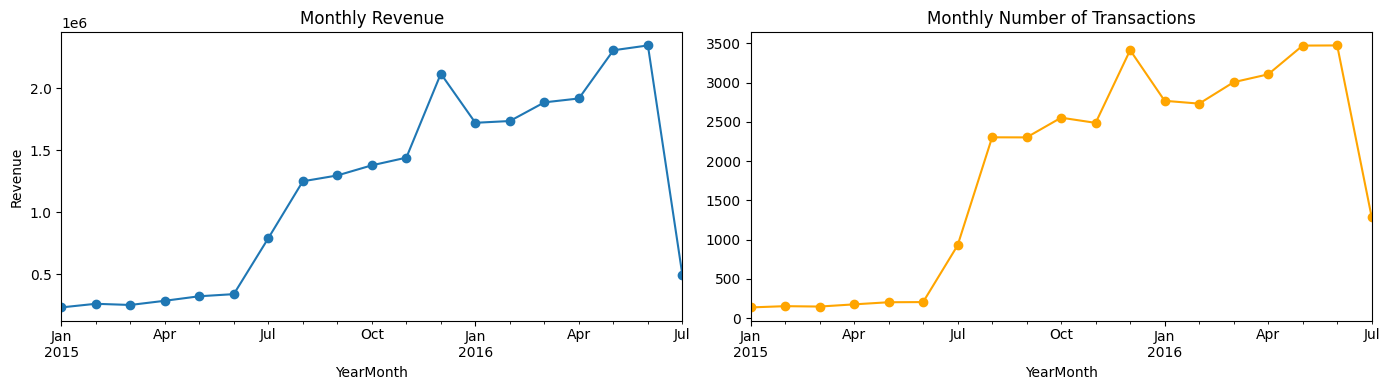

In [8]:
df['YearMonth'] = df['Date'].dt.to_period('M')
monthly = df.groupby('YearMonth').agg(
    Revenue=('Revenue', 'sum'),
    Transactions=('Revenue', 'count')
)
print(monthly)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
monthly['Revenue'].plot(ax=ax[0], marker='o')
ax[0].set_title("Monthly Revenue")
ax[0].set_ylabel("Revenue")
monthly['Transactions'].plot(ax=ax[1], marker='o', color='orange')
ax[1].set_title("Monthly Number of Transactions")
plt.tight_layout()
plt.savefig("monthly_trend.png", dpi=150)
plt.show()

In [9]:
cat_month = pd.crosstab(df['YearMonth'], df['Product Category'])
print(cat_month)

# Last dates in the data, to check whether July 2016 is complete
print("\nTransactions per day in July 2016 (last 10 days):")
print(df[df['YearMonth'] == '2016-07'].groupby('Date').size().tail(10))

Product Category  Accessories  Bikes  Clothing
YearMonth                                     
2015-01                     0    138         0
2015-02                     0    154         0
2015-03                     0    149         0
2015-04                     0    177         0
2015-05                     0    204         0
2015-06                     0    206         0
2015-07                   457    355       116
2015-08                  1601    357       346
2015-09                  1560    372       371
2015-10                  1751    408       395
2015-11                  1668    455       365
2015-12                  2180    746       488
2016-01                  1874    452       443
2016-02                  1828    489       416
2016-03                  2015    522       469
2016-04                  2056    535       515
2016-05                  2281    679       512
2016-06                  2210    695       569
2016-07                  1053      0       234

Transactions

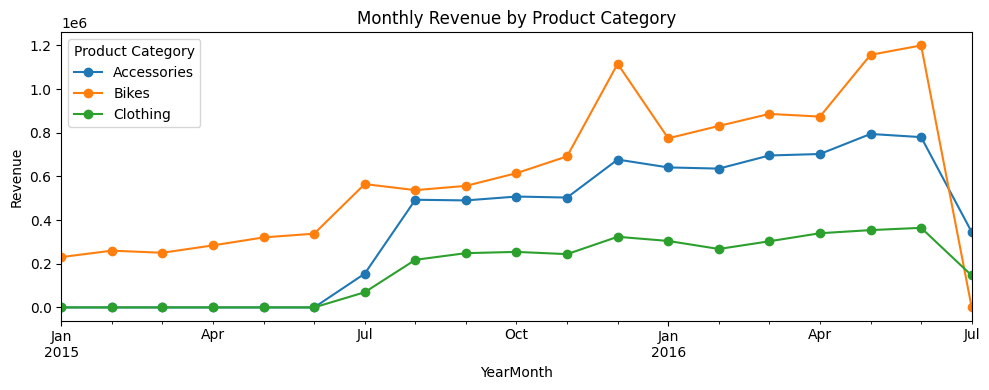

Quarter
2015Q1     740764.0
2015Q2     942528.0
2015Q3    3332485.0
2015Q4    4931994.0
2016Q1    5339426.0
2016Q2    6565767.0
2016Q3     491612.0
Freq: Q-DEC, Name: Revenue, dtype: float64


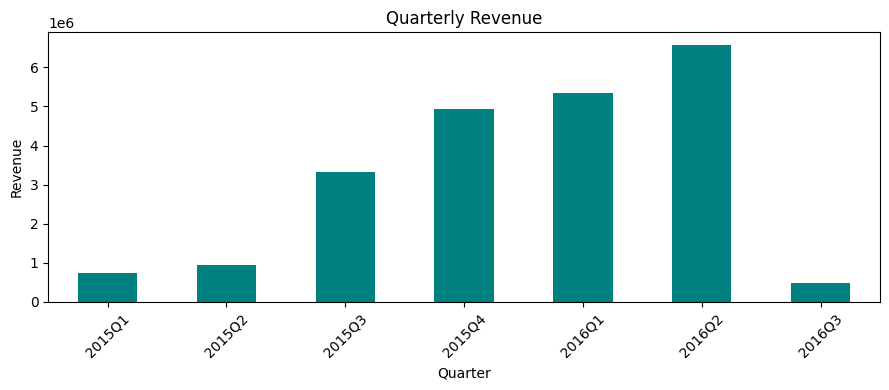

In [10]:
# Monthly revenue by product category
rev_cat = df.pivot_table(index='YearMonth', columns='Product Category',
                         values='Revenue', aggfunc='sum').fillna(0)
rev_cat.plot(figsize=(10, 4), marker='o')
plt.title("Monthly Revenue by Product Category")
plt.ylabel("Revenue")
plt.tight_layout()
plt.savefig("monthly_revenue_by_category.png", dpi=150)
plt.show()

# Quarterly revenue
df['Quarter'] = df['Date'].dt.to_period('Q')
quarterly = df.groupby('Quarter')['Revenue'].sum()
print(quarterly)

quarterly.plot(kind='bar', figsize=(9, 4), color='teal')
plt.title("Quarterly Revenue")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("quarterly_revenue.png", dpi=150)
plt.show()

## Phase 3: Time Series Analysis
### Data coverage finding
- From January to June 2015, the data contains **only Bikes**. Accessories and Clothing first appear in July 2015.
- Because of this, the jump in total revenue and transactions from July 2015 (206 to 928 transactions, and 2,304 in August) reflects broader product coverage, **not** genuine sales growth. Total monthly figures before and after July 2015 are therefore not directly comparable.
- July 2016 contains **no Bikes transactions**, although all 31 days have sales. The drop in July 2016 revenue is therefore a data gap, not a real decline.
- Bikes alone grow steadily, from 138 transactions in January 2015 to 695 in June 2016, with a peak in December 2015.

### Quarterly revenue
| Quarter | Revenue |
|---|---|
| 2015 Q1 | 740,764 |
| 2015 Q2 | 942,528 |
| 2015 Q3 | 3,332,485 |
| 2015 Q4 | 4,931,994 |
| 2016 Q1 | 5,339,426 |
| 2016 Q2 | 6,565,767 |
| 2016 Q3 | 491,612 (July only, no Bikes) |

- The jump in 2015 Q3 comes mainly from Accessories and Clothing entering the data, so earlier quarters are not comparable with later ones.
- Like-for-like growth is visible from 2015 Q4 onwards: revenue rose about 8% in 2016 Q1 and about 23% in 2016 Q2 (quarter over quarter).
- 2016 Q3 covers only July and has no Bikes data, so it is excluded from trend conclusions.
- Revenue peaks in December 2015 (holiday season), driven by all three categories.

Transactions by age group:
Age Group
17-24     5157
25-34    11606
35-44    10075
45-54     5730
55+       2298
Name: count, dtype: int64

Transactions by gender:
Customer Gender
M    17805
F    17061
Name: count, dtype: int64

Revenue by gender:
Customer Gender
F    10932634.0
M    11411942.0
Name: Revenue, dtype: float64

Average revenue per transaction by age group:
Age Group
17-24    493.34
25-34    675.84
35-44    691.74
45-54    645.54
55+      560.62
Name: Revenue, dtype: float64


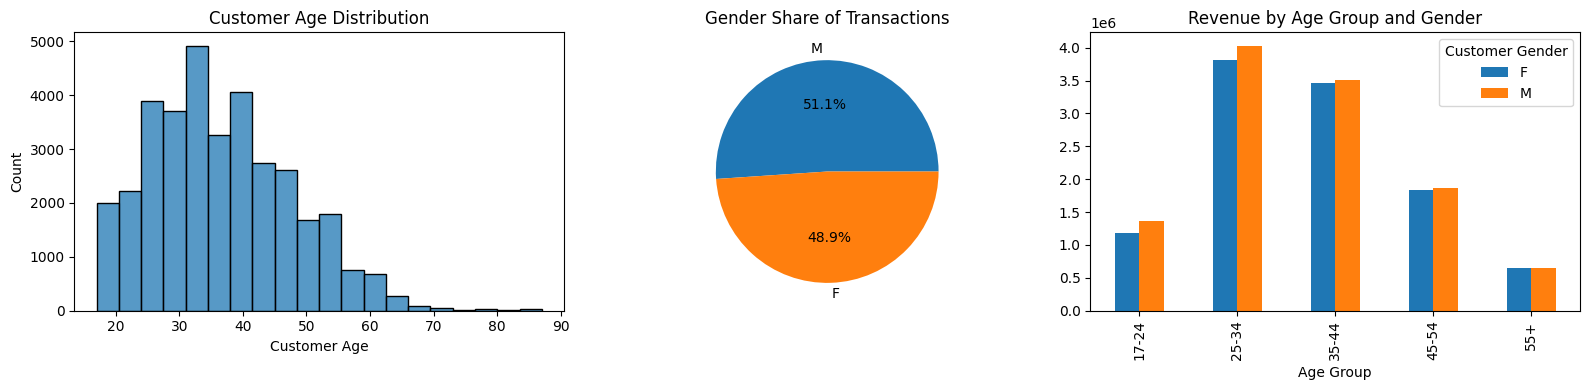

In [11]:
bins = [16, 24, 34, 44, 54, 100]
labels = ['17-24', '25-34', '35-44', '45-54', '55+']
df['Age Group'] = pd.cut(df['Customer Age'], bins=bins, labels=labels)

print("Transactions by age group:")
print(df['Age Group'].value_counts().sort_index())
print("\nTransactions by gender:")
print(df['Customer Gender'].value_counts())
print("\nRevenue by gender:")
print(df.groupby('Customer Gender')['Revenue'].sum())
print("\nAverage revenue per transaction by age group:")
print(df.groupby('Age Group', observed=True)['Revenue'].mean().round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['Customer Age'], bins=20, ax=ax[0])
ax[0].set_title("Customer Age Distribution")
df['Customer Gender'].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=ax[1])
ax[1].set_title("Gender Share of Transactions")
ax[1].set_ylabel("")
rev_ag = df.pivot_table(index='Age Group', columns='Customer Gender',
                        values='Revenue', aggfunc='sum', observed=True)
rev_ag.plot(kind='bar', ax=ax[2])
ax[2].set_title("Revenue by Age Group and Gender")
plt.tight_layout()
plt.savefig("demographics.png", dpi=150)
plt.show()

## Phase 4: Customer Demographics
Note: the dataset has no customer ID, so all counts below are transactions, not unique customers.

| Age Group | Transactions | Share | Avg Revenue per Transaction |
|---|---|---|---|
| 17-24 | 5,157 | 14.8% | 493.34 |
| 25-34 | 11,606 | 33.3% | 675.84 |
| 35-44 | 10,075 | 28.9% | 691.74 |
| 45-54 | 5,730 | 16.4% | 645.54 |
| 55+ | 2,298 | 6.6% | 560.62 |

| Gender | Transactions | Revenue |
|---|---|---|
| Male | 17,805 | 11,411,942 |
| Female | 17,061 | 10,932,634 |

**Observations**
- Customers aged 25-44 account for about 62% of transactions, so they are the core audience.
- Customers aged 35-44 spend the most per transaction (691.74), while the 17-24 group spends the least (493.34).
- Gender split is almost even (51% male, 49% female) and average revenue per transaction is nearly identical (about 641), so gender does not noticeably change spending.

Top 10 best-selling sub categories:
                   Units_Sold    Revenue
Sub Category                            
Tires and Tubes         22213  2865915.0
Bottles and Cages       10558   709407.0
Helmets                  8387  2738210.0
Road Bikes               6119  3921989.0
Mountain Bikes           5499  5176456.0
Jerseys                  4033  1834110.0
Caps                     3020   255992.0
Touring Bikes            2673  2387910.0
Fenders                  1494   329204.0
Shorts                   1129   689184.0

Revenue and profit by product category:
                     Revenue     Profit  Profit Margin %
Product Category                                        
Accessories        7420664.0  1378769.0             18.6
Bikes             11486355.0   337601.0              2.9
Clothing           3437557.0   545232.0             15.9


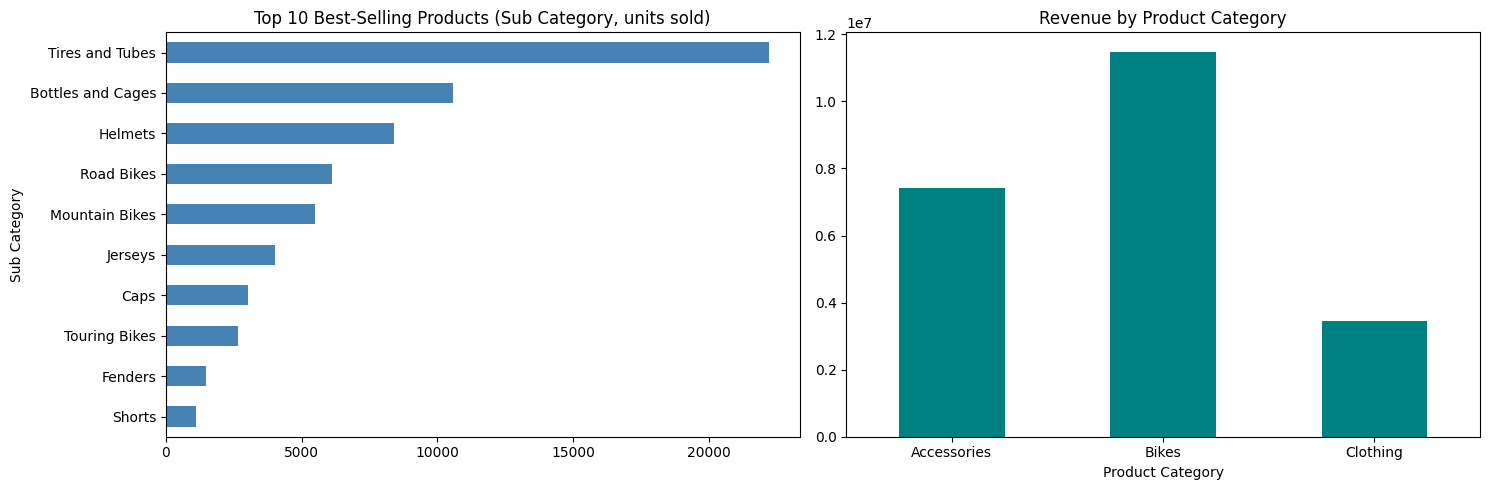

In [12]:
df['Profit'] = df['Revenue'] - df['Cost']

top10 = df.groupby('Sub Category').agg(
    Units_Sold=('Quantity', 'sum'),
    Revenue=('Revenue', 'sum')
).sort_values('Units_Sold', ascending=False).head(10)
print("Top 10 best-selling sub categories:")
print(top10)

cat = df.groupby('Product Category').agg(
    Revenue=('Revenue', 'sum'),
    Profit=('Profit', 'sum')
)
cat['Profit Margin %'] = (cat['Profit'] / cat['Revenue'] * 100).round(1)
print("\nRevenue and profit by product category:")
print(cat)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
top10['Units_Sold'].sort_values().plot(kind='barh', ax=ax[0], color='steelblue')
ax[0].set_title("Top 10 Best-Selling Products (Sub Category, units sold)")
cat['Revenue'].plot(kind='bar', ax=ax[1], color='teal')
ax[1].set_title("Revenue by Product Category")
ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig("product_analysis.png", dpi=150)
plt.show()

## Phase 5: Product Analysis
Note: product analysis uses Sub Category as the product level. Bikes cover Jan 2015 to Jun 2016, while Accessories and Clothing appear only from July 2015, so absolute totals are not fully like-for-like. Profit = Revenue - Cost, as per the dataset's Cost column.

### Top 10 best-selling products (by units sold)
| Sub Category | Units Sold | Revenue |
|---|---|---|
| Tires and Tubes | 22,213 | 2,865,915 |
| Bottles and Cages | 10,558 | 709,407 |
| Helmets | 8,387 | 2,738,210 |
| Road Bikes | 6,119 | 3,921,989 |
| Mountain Bikes | 5,499 | 5,176,456 |
| Jerseys | 4,033 | 1,834,110 |
| Caps | 3,020 | 255,992 |
| Touring Bikes | 2,673 | 2,387,910 |
| Fenders | 1,494 | 329,204 |
| Shorts | 1,129 | 689,184 |

### Revenue and profit by category
| Category | Revenue | Profit | Profit Margin |
|---|---|---|---|
| Accessories | 7,420,664 | 1,378,769 | 18.6% |
| Bikes | 11,486,355 | 337,601 | 2.9% |
| Clothing | 3,437,557 | 545,232 | 15.9% |

**Observations**
- Tires and Tubes sell the most units (22,213), but Mountain Bikes and Road Bikes generate the most revenue. Units sold and revenue rank products very differently.
- Bikes bring in the highest revenue (about 51% of the total) but earn only a 2.9% margin, contributing roughly 15% of total profit.
- Accessories and Clothing have much healthier margins (18.6% and 15.9%) and together contribute about 85% of total profit.

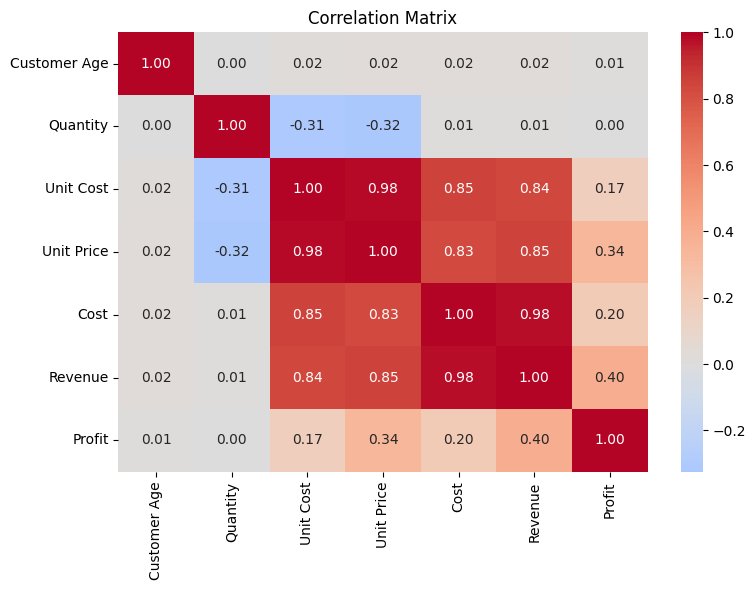

                     Revenue    Profit  Margin %
Sub Category                                    
Road Bikes         3921989.0   98166.0       2.5
Mountain Bikes     5176456.0  144627.0       2.8
Touring Bikes      2387910.0   94808.0       4.0
Shorts              689184.0   87044.0      12.6
Socks                61237.0    9541.0      15.6
Vests               368681.0   58344.0      15.8
Jerseys            1834110.0  300876.0      16.4
Bike Stands         150911.0   25301.0      16.8
Caps                255992.0   43610.0      17.0
Cleaners             82887.0   14664.0      17.7
Tires and Tubes    2865915.0  512124.0      17.9
Hydration Packs     403276.0   72341.0      17.9
Bottles and Cages   709407.0  129567.0      18.3
Helmets            2738210.0  518475.0      18.9
Gloves              228353.0   45817.0      20.1
Fenders             329204.0   71403.0      21.7
Bike Racks          140854.0   34894.0      24.8


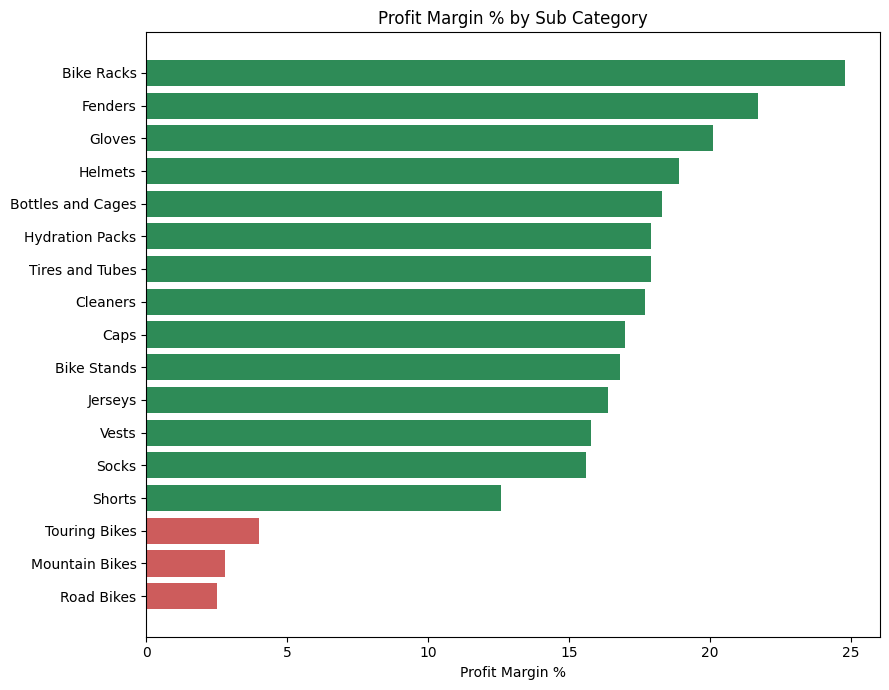

In [13]:
# Correlation heatmap
corr_cols = ['Customer Age', 'Quantity', 'Unit Cost', 'Unit Price', 'Cost', 'Revenue', 'Profit']
plt.figure(figsize=(8, 6))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=150)
plt.show()

# Extra insight: profit margin by sub category
sub = df.groupby('Sub Category').agg(Revenue=('Revenue', 'sum'), Profit=('Profit', 'sum'))
sub['Margin %'] = (sub['Profit'] / sub['Revenue'] * 100).round(1)
sub = sub.sort_values('Margin %')
print(sub)

plt.figure(figsize=(9, 7))
colors = ['indianred' if m < 5 else 'seagreen' for m in sub['Margin %']]
plt.barh(sub.index, sub['Margin %'], color=colors)
plt.title("Profit Margin % by Sub Category")
plt.xlabel("Profit Margin %")
plt.tight_layout()
plt.savefig("margin_by_subcategory.png", dpi=150)
plt.show()

## Phase 6: Correlation and Additional Insight
### Additional insight: profit margin by sub category
| Sub Category | Revenue | Profit | Margin |
|---|---|---|---|
| Road Bikes | 3,921,989 | 98,166 | 2.5% |
| Mountain Bikes | 5,176,456 | 144,627 | 2.8% |
| Touring Bikes | 2,387,910 | 94,808 | 4.0% |
| Shorts | 689,184 | 87,044 | 12.6% |
| Jerseys | 1,834,110 | 300,876 | 16.4% |
| Tires and Tubes | 2,865,915 | 512,124 | 17.9% |
| Helmets | 2,738,210 | 518,475 | 18.9% |
| Bike Racks | 140,854 | 34,894 | 24.8% |

(Selected rows shown; the notebook output lists all 17 sub categories.)

- All three Bikes sub categories earn margins below 4%, while every other sub category earns 12.6% or more.
- Helmets earn about 3.5 times the profit of Mountain Bikes (518,475 vs 144,627) on roughly half the revenue.
- Bike Racks have the highest margin (24.8%) but small revenue, so their absolute profit contribution is limited.


### Correlation analysis
- Revenue is strongly correlated with Cost (0.98), Unit Price (0.85) and Unit Cost (0.84). Higher-priced products drive revenue.
- Quantity has almost no correlation with Revenue (0.01), because orders contain only 1 to 3 units. It is negatively correlated with Unit Price (-0.32): cheaper items are bought in larger quantities.
- Customer Age has no meaningful correlation (0.00 to 0.02) with any spending variable, so age alone does not predict how much a customer spends.
- Profit is only moderately correlated with Revenue (0.40), so higher revenue does not automatically mean higher profit. This matches the low margins found on Bikes.

## Phase 7: Conclusion and Recommendations
### Key findings
- The store's revenue grew steadily from late 2015 to mid 2016, with a peak in December 2015. Early comparisons are distorted because Accessories and Clothing appear in the data only from July 2015.
- Bikes generate about 51% of revenue but only about 15% of profit (margin 2.9%). Accessories and Clothing earn margins of 18.6% and 15.9%.
- Customers aged 25-44 make up about 62% of transactions. Customers aged 35-44 spend the most per transaction, and gender has no noticeable effect on spending.

### Recommendations
1. **Review Bikes pricing and costs.** All three bike types earn margins below 4%, so small cost increases or discounts can erase profit. The store should renegotiate supplier costs or adjust prices and discounts on Road, Mountain and Touring Bikes.
2. **Bundle high-margin accessories with bike sales.** Helmets earned about 3.5 times the profit of Mountain Bikes, and most accessories have margins above 17%. Offering helmets, gloves, bottles and tires with every bike purchase would lift profit per customer.
3. **Focus marketing on customers aged 25-44.** They are the largest group and 35-44 year olds spend the most per transaction. For the 17-24 group (lowest spend per transaction), entry-level products and offers could raise their spending. Since gender does not affect spending, campaigns do not need to be gender-specific.

### Limitations
- The dataset has no customer ID, so counts are transactions, not unique customers.
- Product coverage differs by period (no Accessories or Clothing before July 2015, and no Bikes in July 2016), so period-to-period comparisons of total revenue should be treated with caution.
- Profit is calculated from the dataset's Cost column, whose exact definition is not documented.